In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt


In [2]:
# Constants
LATENT_DIM = 32        # Size of noise vector for generator input
BATCH_SIZE = 1000       # Batch size for training
EPOCHS = 1000          # Number of training epochs
LEARNING_RATE = 0.0002 # Learning rate for Adam optimizers
BETAS = (0.5, 0.999)   # Betas for Adam optimizers
RANDOM_STATE = 1082    # Random seed for reproducibility

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Set numpy random seed
np.random.seed(RANDOM_STATE)
# Set torch random seed
torch.manual_seed(RANDOM_STATE)
# If using CUDA
if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_STATE)
    torch.cuda.manual_seed_all(RANDOM_STATE)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

Conditional GAN for tabular data
- Generator: learns to generate fake tabular data conditioned on class labels.
- Discriminator: learns to distinguish real vs. fake samples, given labels.
- Training alternates between D and G updates, as in standard GANs.

In [4]:
class cGAN_Tabular:
    def __init__(self, data_dim, n_classes, latent_dim=LATENT_DIM, device=None):
        self.latent_dim = latent_dim
        self.data_dim = data_dim
        self.n_classes = n_classes
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")

        self.G = self.build_generator().to(self.device)
        self.D = self.build_discriminator().to(self.device)

        self.criterion = nn.BCELoss()
        self.optim_G = optim.Adam(self.G.parameters(), lr=LEARNING_RATE, betas=BETAS)
        self.optim_D = optim.Adam(self.D.parameters(), lr=LEARNING_RATE, betas=BETAS)

    def build_generator(self):
        return nn.Sequential(
            nn.Linear(self.latent_dim + self.n_classes, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, self.data_dim)
        )

    def build_discriminator(self):
        return nn.Sequential(
            nn.Linear(self.data_dim + self.n_classes, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.4),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def train(self, X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, sample_interval=100, plot=True):
        # Prepare one-hot labels
        y_train = torch.tensor(y_train, dtype=torch.long)
        X_train = torch.tensor(X_train, dtype=torch.float32)
        dataset = torch.utils.data.TensorDataset(X_train, y_train)
        dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

        G_losses, D_losses = [], []

        for epoch in range(epochs):
            for real_data, real_labels in dataloader:
                real_data = real_data.to(self.device)
                real_labels = real_labels.to(self.device)
                batch_sz = real_data.size(0)
                real_onehot = torch.nn.functional.one_hot(real_labels, num_classes=self.n_classes).float()

                # Train Discriminator
                self.D.train()
                self.D.zero_grad()
                # Real samples
                valid = torch.ones((batch_sz, 1), device=self.device)
                fake = torch.zeros((batch_sz, 1), device=self.device)

                D_input_real = torch.cat([real_data, real_onehot], dim=1)
                D_real = self.D(D_input_real)
                d_loss_real = self.criterion(D_real, valid)

                # Fake samples
                noise = torch.randn(batch_sz, self.latent_dim, device=self.device)
                fake_labels = torch.randint(0, self.n_classes, (batch_sz,), device=self.device)
                fake_onehot = torch.nn.functional.one_hot(fake_labels, num_classes=self.n_classes).float()
                G_input = torch.cat([noise, fake_onehot], dim=1)
                fake_data = self.G(G_input)
                D_input_fake = torch.cat([fake_data.detach(), fake_onehot], dim=1)
                D_fake = self.D(D_input_fake)
                d_loss_fake = self.criterion(D_fake, fake)

                d_loss = 0.5 * (d_loss_real + d_loss_fake)
                d_loss.backward()
                self.optim_D.step()

                # Train Generator
                self.G.train()
                self.G.zero_grad()
                # Generate again for generator step
                G_input = torch.cat([noise, fake_onehot], dim=1)
                fake_data = self.G(G_input)
                D_input_fake = torch.cat([fake_data, fake_onehot], dim=1)
                D_fake = self.D(D_input_fake)
                g_loss = self.criterion(D_fake, valid)
                g_loss.backward()
                self.optim_G.step()

            G_losses.append(g_loss.item())
            D_losses.append(d_loss.item())

            if (epoch+1) % sample_interval == 0 or epoch == 0:
                print(f'[{epoch+1}/{epochs}]\tLoss_D: {d_loss.item():.4f}\tLoss_G: {g_loss.item():.4f}')

        if plot:
            plt.figure(figsize=(10, 5))
            plt.title("Generator and Discriminator Loss")
            plt.plot(G_losses, label="G")
            plt.plot(D_losses, label="D")
            plt.xlabel("Epoch")
            plt.ylabel("Loss")
            plt.legend()
            plt.show()
        return G_losses, D_losses

    def generate(self, num_samples, label_value, scaler=None):
        self.G.eval()
        z = torch.randn(num_samples, self.latent_dim, device=self.device)
        labels = torch.full((num_samples,), label_value, dtype=torch.long, device=self.device)
        labels_onehot = torch.nn.functional.one_hot(labels, num_classes=self.n_classes).float()
        G_input = torch.cat([z, labels_onehot], dim=1)
        with torch.no_grad():
            synth = self.G(G_input).cpu().numpy()
        if scaler is not None:
            synth = scaler.inverse_transform(synth)
        return synth

In [5]:
from gps_ids import protocol, schema

EXP = protocol.real_heldout("uav")
feature_names = EXP.feature_names


In [6]:
print("Train shape:", EXP.X_train.shape)
print("Label distribution:", np.bincount(EXP.y_train))


Train shape: (2897, 82)
Label distribution: [2499  398]


In [7]:
n_classes = len(EXP.labels)
scaler = EXP.scaler
X_train = EXP.X_train.values
X_test = EXP.X_test.values
y_train = EXP.y_train
y_test = EXP.y_test


[1/1000]	Loss_D: 0.6872	Loss_G: 0.6813


[100/1000]	Loss_D: 0.5932	Loss_G: 1.2502


[200/1000]	Loss_D: 0.5246	Loss_G: 1.3516


[300/1000]	Loss_D: 0.5428	Loss_G: 1.2805


[400/1000]	Loss_D: 0.5766	Loss_G: 1.2024


[500/1000]	Loss_D: 0.5191	Loss_G: 1.2422


[600/1000]	Loss_D: 0.5303	Loss_G: 1.2140


[700/1000]	Loss_D: 0.5583	Loss_G: 1.2517


[800/1000]	Loss_D: 0.4934	Loss_G: 1.2475


[900/1000]	Loss_D: 0.5752	Loss_G: 1.2584


[1000/1000]	Loss_D: 0.5355	Loss_G: 1.2648


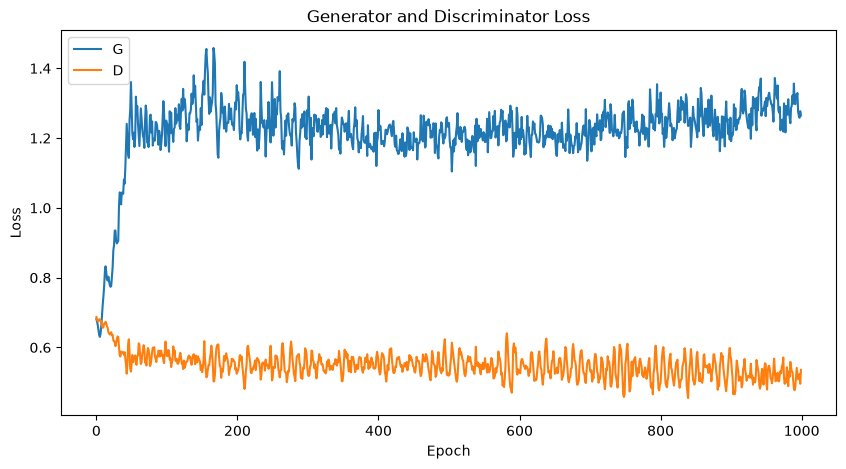

In [8]:
# Train cGAN
cgan = cGAN_Tabular(
    data_dim=X_train.shape[1],
    n_classes=n_classes,
    latent_dim=LATENT_DIM
)
G_losses, D_losses = cgan.train(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, sample_interval=100, plot=True)

In [9]:
per_class = len(y_train) // len(EXP.labels)

frames = []
labels = []
for cls in EXP.labels:
    samples = cgan.generate(per_class, label_value=cls, scaler=scaler)
    frames.append(pd.DataFrame(samples, columns=feature_names))
    labels.append(np.full(per_class, cls, dtype=int))

df_gan = pd.concat(frames, ignore_index=True, sort=False)
df_gan["label"] = np.concatenate(labels)
df_gan = df_gan.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)


In [10]:
# Preview the synthetic data
print("\nSynthetic Data Preview: ")
print(df_gan.head())
print("\nSynthetic data shape:", df_gan.shape)
print("\nSynthetic label distribution:")
print(df_gan['label'].value_counts())


Synthetic Data Preview: 
       q_0_      q_1_      q_2_      q_3_  delta_q_reset_0_  delta_q_reset_1_  \
0 -0.477677  0.062812 -0.060385  0.847316          1.082731          0.097956   
1 -0.400437  0.002833  0.064980  0.897731          1.094105          0.035036   
2 -0.326189  0.290223 -0.378625  0.755157          0.819636         -0.244266   
3 -0.160712  0.112254 -1.000482 -0.068500          0.967922         -0.097713   
4 -0.188206  0.230709 -1.001741  0.042755          0.977360         -0.171551   

   delta_q_reset_2_  delta_q_reset_3_  quat_reset_counter      lat_x  ...  \
0          0.016313          0.177451            2.916061  36.204895  ...   
1         -0.002769         -0.041326            3.002178  36.204838  ...   
2         -0.095348          0.137339            2.874837  36.204948  ...   
3         -0.062911          0.081922            2.898553  36.204948  ...   
4          0.026401          0.127602            2.891427  36.204967  ...   

   v_z_valid  xy_reset_c

In [11]:
out_path = schema.write_synthetic(
    df_gan.drop(columns=["label"]),
    df_gan["label"],
    "uav",
    "syntheticSpoofing_cgan_data.csv",
)
print(f"Synthetic data saved to {out_path}")


Synthetic data saved to /workspace/project/Image-Based-Intrusion-Detection-System-for-Global-Positioning-System-Spoofing-in-Unmanned-Aerial-Veh/Datasets/csv/UAVATTACK/syntheticSpoofing_cgan_data.csv
